### 1.3.1

In [3]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Загрузка данных (60 объектов × 10 признаков, без заголовка)
df = pd.read_csv('8_36.csv', header=None)
X = df.values
print("Размер данных:", X.shape)  # должно быть (60, 10)

# 2. Стандартизация (центрирование + масштабирование)
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

# 3. PCA
pca = PCA()
# X_pca = pca.fit_transform(X_scaled)
X_pca = pca.fit_transform(X)

# --- Ответ 1: координата 1-го объекта по PC1 ---
ans1 = X_pca[0, 0]
print(f"1) PC1 первого объекта: {ans1:.3f}")

# --- Ответ 2: координата 1-го объекта по PC2 ---
ans2 = X_pca[0, 1]
print(f"2) PC2 первого объекта: {ans2:.3f}")

# --- Ответ 3: доля объяснённой дисперсии первых двух PC ---
ans3 = pca.explained_variance_ratio_[:2].sum()
print(f"3) Доля дисперсии PC1+PC2: {ans3:.3f}")

# --- Ответ 4: минимальное число PC для доли > 0.85 ---
cumulative = np.cumsum(pca.explained_variance_ratio_)
ans4 = int(np.argmax(cumulative > 0.85) + 1)
print(f"4) Минимум PC для > 0.85: {ans4}")

# --- Ответ 5: число групп по первым двум PC ---
X_2d = X_pca[:, :2]
best_k, best_score = 2, -1
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_2d)
    score = silhouette_score(X_2d, labels)
    if score > best_score:
        best_score, best_k = score, k
print(f"5) Оптимальное число групп по PC1+PC2: {best_k} (silhouette={best_score:.3f})")

Размер данных: (60, 10)
1) PC1 первого объекта: -33.152
2) PC2 первого объекта: 22.022
3) Доля дисперсии PC1+PC2: 0.535
4) Минимум PC для > 0.85: 4
5) Оптимальное число групп по PC1+PC2: 5 (silhouette=0.860)


### 1.3.2

T: (100, 10)
P: (100, 10)


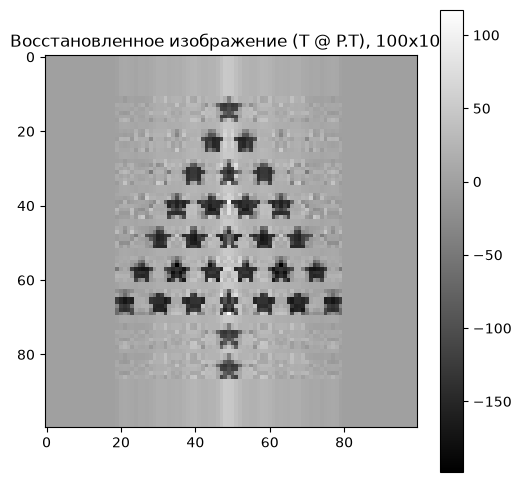

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

T = pd.read_csv('X_reduced_561.csv', header=None, sep=';').values
P = pd.read_csv('X_loadings_561.csv', header=None, sep=';').values

print("T:", T.shape)  # (100, 10)
print("P:", P.shape)  # (100, 10)

# Восстановление: X_rec = T @ P.T  -> (100, 10) @ (10, 100) = (100, 100)
X_rec = T @ P.T

# Визуализация как изображение 100x100
plt.figure(figsize=(6, 6))
plt.imshow(X_rec, cmap='gray')
plt.colorbar()
plt.title('Восстановленное изображение (T @ P.T), 100x100')
plt.show()

### 2.2

In [10]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Загрузка данных (разделитель — запятая)
df = pd.read_csv('14_25.csv', header=None)
X = df.values
print("Размер данных:", X.shape)  # (60, 10)

# 2. Стандартизация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# --- 1. Координата 1-го объекта по PC1 ---
ans1 = X_pca[0, 0]
print(f"1) PC1 первого объекта: {ans1:.3f}")

# --- 2. Координата 1-го объекта по PC2 ---
ans2 = X_pca[0, 1]
print(f"2) PC2 первого объекта: {ans2:.3f}")

# --- 3. Доля объяснённой дисперсии первых двух PC ---
ans3 = pca.explained_variance_ratio_[:2].sum()
print(f"3) Доля дисперсии PC1+PC2: {ans3:.3f}")

# --- 4. Минимальное число PC для доли > 0.85 ---
cumulative = np.cumsum(pca.explained_variance_ratio_)
ans4 = int(np.argmax(cumulative > 0.85) + 1)
print(f"4) Минимум PC для > 0.85: {ans4}")

# --- 5. Число групп по первым двум PC ---
X_2d = X_pca[:, :2]
best_k, best_score = 2, -1
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_2d)
    score = silhouette_score(X_2d, labels)
    if score > best_score:
        best_score, best_k = score, k
print(f"5) Оптимальное число групп: {best_k} (silhouette={best_score:.3f})")

Размер данных: (60, 10)
1) PC1 первого объекта: 3.017
2) PC2 первого объекта: 0.322
3) Доля дисперсии PC1+PC2: 0.732
4) Минимум PC для > 0.85: 3
5) Оптимальное число групп: 5 (silhouette=0.886)


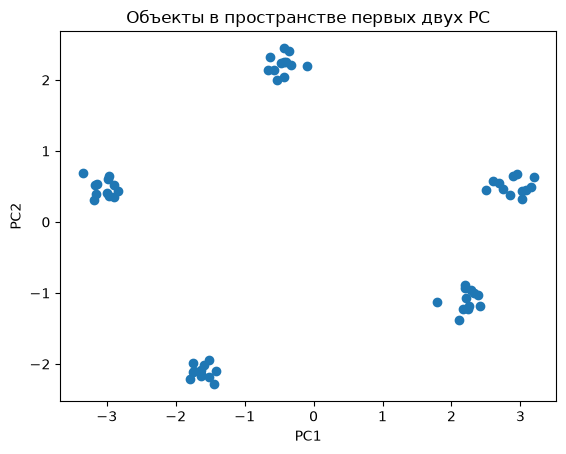

In [11]:
import matplotlib.pyplot as plt
plt.scatter(X_2d[:, 0], X_2d[:, 1])
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Объекты в пространстве первых двух PC')
plt.show()